In [1]:
import os

fun_list = ['SVWN', 'BLYP', 'PBE', 'TPSS', 'B3LYP', 'PBE0']
for fun in fun_list:
    try:
        os.mkdir(fun)
        print(f"Created directory: {fun}")
    except FileExistsError:
        print(f"Directory already exists: {fun}")

Created directory: SVWN
Created directory: BLYP
Created directory: PBE
Created directory: TPSS
Created directory: B3LYP
Created directory: PBE0


In [4]:
for fun in fun_list:
    filename = f"{fun}/Grid.py"
    with open('Grid.py', 'r') as file:
        lines = file.readlines()
        lines[9] = f"fun = '{fun}'\n"
        with open(filename, 'w') as new_file:
            new_file.writelines(lines)

In [3]:
import shutil

for fun in fun_list:
    shutil.copy('wt_sub_py.sh', f"{fun}/wt_sub_py.sh")

In [1]:
import numpy as np

fun_list = ['SVWN', 'BLYP', 'PBE', 'TPSS', 'B3LYP', 'PBE0']
Ediff = {}
Gdiff = {}

for fun in fun_list:
    Exe = np.load(f'{fun}/ExcitationEnergy.npy')
    ref = Exe[-1]
    Exe = Exe[:-1]
    mae  = np.mean(np.abs(Exe-ref), axis=1)
    Ediff[fun] = mae
    Grad = np.load(f'{fun}/Gradient.npy')
    ref = Grad[-1]
    Grad = Grad[:-1]
    mae  = np.mean(np.abs(Grad-ref), axis=(1,2,3))
    Gdiff[fun] = mae

In [17]:
Ediff

{'SVWN': array([1.73684208e-04, 1.15467860e-06, 1.23107106e-07, 7.64150665e-08,
        1.78566416e-09, 2.39330525e-10, 2.91119115e-10, 6.33991095e-11,
        5.04288211e-11]),
 'BLYP': array([2.62598645e-04, 1.51060674e-06, 9.80578744e-08, 1.04868160e-07,
        2.76287680e-09, 3.68360512e-09, 2.35363612e-09, 2.17194255e-09,
        1.97904178e-09]),
 'PBE': array([4.98864329e-04, 2.83044667e-06, 1.51125943e-07, 1.13312810e-07,
        1.15761154e-08, 6.13228923e-09, 1.63215669e-09, 4.87595183e-09,
        4.20679203e-09]),
 'TPSS': array([1.18803417e-03, 1.20356106e-05, 6.06639396e-07, 4.66199866e-07,
        6.49608087e-08, 8.75655132e-08, 5.78533299e-08, 1.88646195e-08,
        1.75418414e-08]),
 'B3LYP': array([1.76715054e-04, 1.03760241e-06, 8.76946685e-08, 9.05735160e-08,
        1.98350921e-09, 2.84460186e-09, 2.12401815e-09, 1.52342523e-09,
        1.42059616e-09]),
 'PBE0': array([3.77654933e-04, 1.47997436e-06, 1.45663541e-07, 1.12357412e-07,
        1.01253302e-08, 5.2465

In [18]:
Gdiff

{'SVWN': array([1.16357357e-03, 1.27048963e-05, 8.99662585e-07, 1.25765353e-06,
        3.62995236e-08, 1.70034287e-08, 2.72126731e-09, 2.11832449e-09,
        2.68819979e-09]),
 'BLYP': array([1.23454926e-03, 1.53109394e-05, 8.36090514e-07, 1.16876251e-06,
        1.03675999e-07, 2.49929585e-08, 6.37429751e-09, 8.07862610e-09,
        8.86360926e-09]),
 'PBE': array([1.60547987e-03, 2.08547410e-05, 1.16605004e-06, 1.33912717e-06,
        1.53254117e-07, 1.82525205e-08, 1.84590220e-08, 1.24962919e-08,
        1.26351579e-08]),
 'TPSS': array([2.40009690e-03, 3.75646004e-05, 1.88597247e-06, 1.63381458e-06,
        2.76237145e-07, 7.67360797e-08, 1.24359976e-07, 1.37842666e-07,
        1.36020262e-07]),
 'B3LYP': array([1.01158768e-03, 1.20979643e-05, 6.94235000e-07, 9.50031943e-07,
        7.66392988e-08, 1.93220813e-08, 5.63404601e-09, 5.89989449e-09,
        6.54410444e-09]),
 'PBE0': array([1.34024665e-03, 1.63146961e-05, 9.89920107e-07, 1.05903792e-06,
        1.20182730e-07, 1.2378

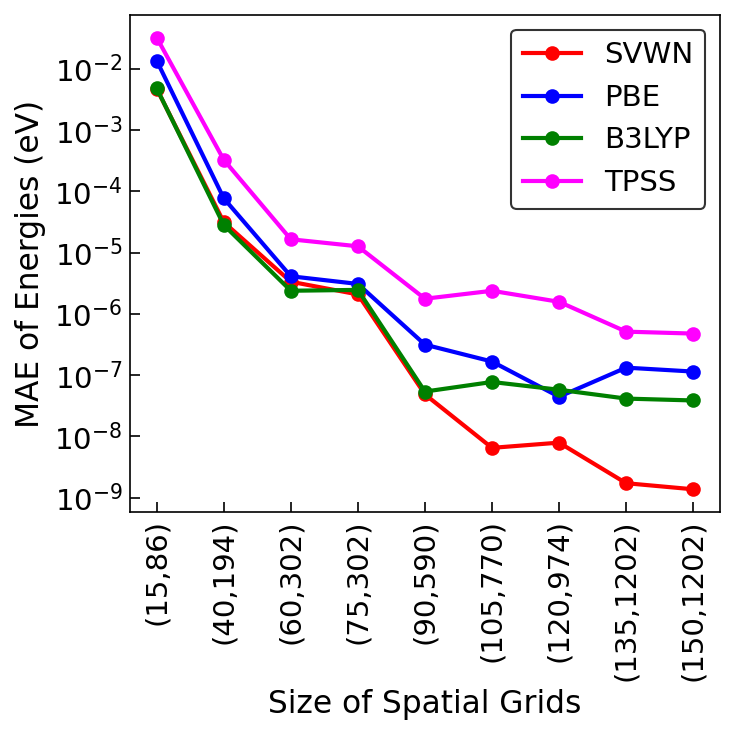

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator

fun_list = ['SVWN', 'PBE', 'B3LYP', 'TPSS']
colors = ['#FF0000', '#0000FF', '#008000', '#FF00FF', '#00FFFF', '#FFA500']
xtick_labels = ['(15,86)', '(40,194)', '(60,302)', '(75,302)', '(90,590)',
                '(105,770)', '(120,974)', '(135,1202)', '(150,1202)']

x = np.arange(len(next(iter(Ediff.values()))))
fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
for fun in fun_list:
    ax.plot(x, Ediff[fun]*27.2114, marker='o', label=fun, linestyle='-', linewidth=2, color=colors[fun_list.index(fun)])
ax.set_yscale('log')
ax.set_xlabel("Size of Spatial Grids", fontsize=15)
ax.set_ylabel("MAE of Energies (eV)", fontsize=15)
ax.tick_params(direction='in', length=5)
ax.yaxis.set_minor_locator(NullLocator())
ax.legend(fontsize=14, loc='upper right', frameon=True, edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, rotation=90)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
# plt.show()
plt.savefig('EnergyXC.png', dpi=600, bbox_inches='tight', pad_inches=0.1)

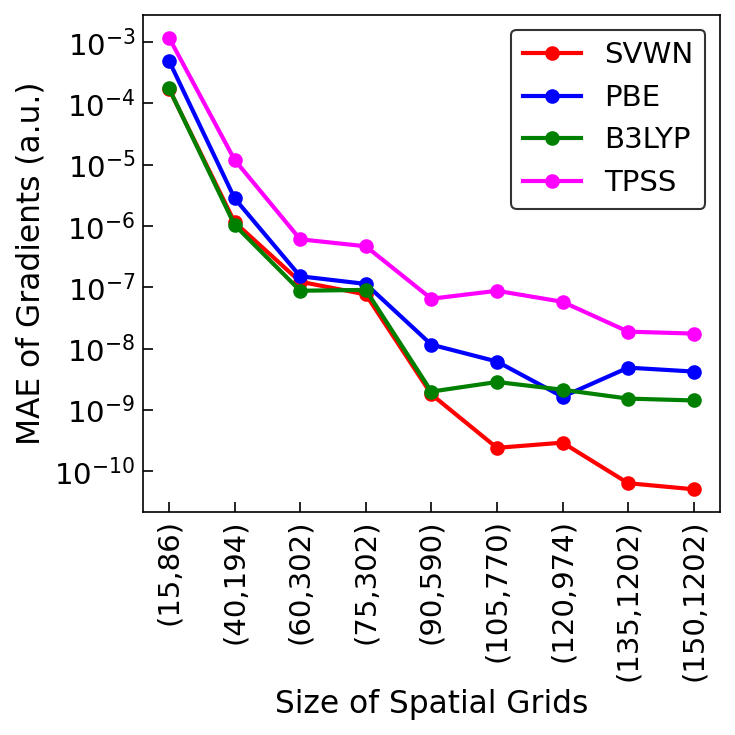

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator

fun_list = ['SVWN', 'PBE', 'B3LYP', 'TPSS']
colors = ['#FF0000', '#0000FF', '#008000', '#FF00FF', '#00FFFF', '#FFA500']
xtick_labels = ['(15,86)', '(40,194)', '(60,302)', '(75,302)', '(90,590)',
                '(105,770)', '(120,974)', '(135,1202)', '(150,1202)']

x = np.arange(len(next(iter(Ediff.values()))))
fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
for fun in fun_list:
    ax.plot(x, Ediff[fun], marker='o', label=fun, linestyle='-', linewidth=2, color=colors[fun_list.index(fun)])
ax.set_yscale('log')
ax.set_xlabel("Size of Spatial Grids", fontsize=15)
ax.set_ylabel("MAE of Gradients (a.u.)", fontsize=15)
ax.tick_params(direction='in', length=5)
ax.yaxis.set_minor_locator(NullLocator())
ax.legend(fontsize=14, loc='upper right', frameon=True, edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, rotation=90)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
# plt.show()
plt.savefig('GradientXC.png', dpi=600, bbox_inches='tight', pad_inches=0.1)